Sujet :  « Anticipations d'inflation »
C'est une régression sur séries mensuelles, avec les algorithmes 1, 2 et 3. Votre fichier est quotidien, donc il faudra l'agréger au mois. Pouvez-vous confirmer que c'est bien F22 ? Sinon, F3 (prévision de l'inflation) est également possible.

**Problématique **: Le niveau des anticipations d'inflation à 10 ans du mois précédent et son historique récent permettent-ils de mieux prévoir le T10YIE du mois suivant qu'une simple persistance ?

Objectif mesurable (fixé avant les résultats) :

Cible : T10YIE moyen du mois t+1.
Variables : valeurs retardées (t, t−1, t−2, …), variation sur 1 mois, moyenne mobile sur 3 mois et volatilité sur 3 mois, toutes calculées uniquement avec le passé.
Découpage chronologique : environ 70 % entraînement, 15 % validation, 15 % test.
Référence naïve : persistance (la valeur du mois t prédit celle de t+1).
Métrique principale : RMSE sur le test. Métrique secondaire : MAE.
Critère de réussite : le modèle est jugé meilleur s’il obtient un RMSE inférieur à celui de la persistance. Sinon, on conclut honnêtement que la série est quasi marche aléatoire.

In [1]:
# Importation des bibliothèques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, learning_curve, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Reproductibilité et style des graphiques
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

In [5]:
# Chargement du jeu de données depuis une URL publique
URL = "/content/drive/MyDrive/test CC fin 2/T10YIE.csv"
df = pd.read_csv(URL)
print("Dimensions :", df.shape)
df.head()

Dimensions : (6222, 2)


,observation_date,T10YIE
0,2003-01-02,1.64
1,2003-01-03,1.62
2,2003-01-06,1.63
3,2003-01-07,1.62
4,2003-01-08,1.71


# **Première exploration**

In [6]:
# Types des colonnes et nombre de valeurs non renseignées
df.info()
print("\nValeurs manquantes par colonne :")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6222 entries, 0 to 6221
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  6222 non-null   object 
 1   T10YIE            5967 non-null   float64
dtypes: float64(1), object(1)
memory usage: 97.3+ KB

Valeurs manquantes par colonne :
observation_date      0
T10YIE              255
dtype: int64


In [11]:
# Conversion de la date et série quotidienne
df["observation_date"] = pd.to_datetime(df["observation_date"])
df = df.sort_values("observation_date").reset_index(drop=True)
daily = df.set_index("observation_date")["T10YIE"]

print("Manquants :", df["T10YIE"].isna().sum(), "| Doublons de dates :", df["observation_date"].duplicated().sum())

# Agrégation mensuelle : les jours fériés (NaN) sont ignorés, pas imputés
monthly = daily.resample("MS").agg(["mean", "std", "count"])
monthly.columns = ["niveau", "vol_intra", "n_jours"]

# Retrait du dernier mois s'il est incomplet
if monthly["n_jours"].iloc[-1] < 15:
    monthly = monthly.iloc[:-1]
print("Mois disponibles :", len(monthly))

Manquants : 255 | Doublons de dates : 0
Mois disponibles : 286


In [7]:
# Statistiques descriptives des variables numériques
df.describe().round(1)

,T10YIE
count,5967.0
mean,2.1
std,0.4
min,0.0
25%,1.9
50%,2.2
75%,2.4
max,3.0


# E**xploration et prétraitement** : 3 figures commentées, pipeline sans fuite

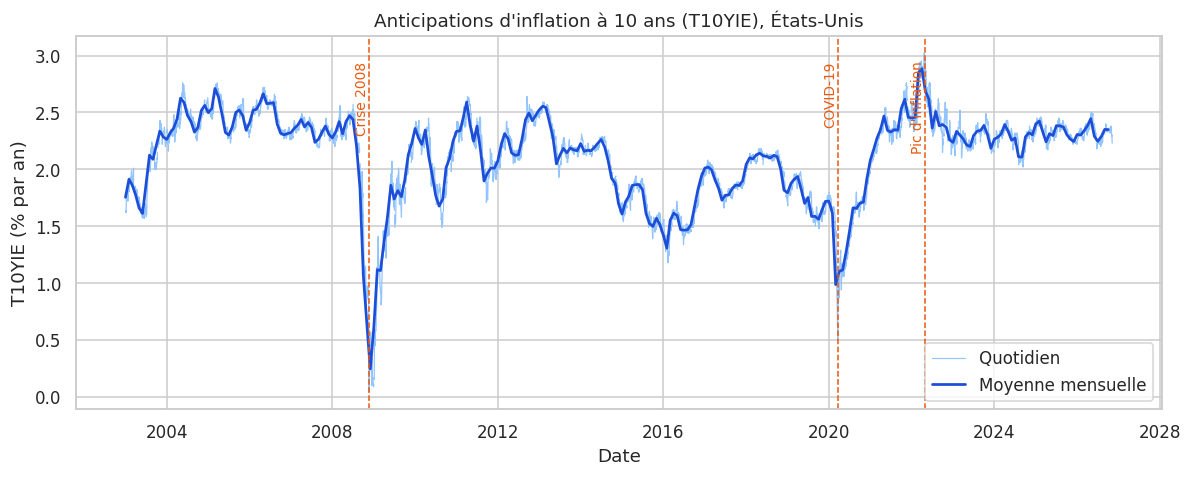

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily.index, daily.values, color="#93c5fd", lw=0.8, label="Quotidien")
ax.plot(monthly.index, monthly["niveau"], color="#1d4ed8", lw=1.8, label="Moyenne mensuelle")
for date, txt in [("2008-11-20", "Crise 2008"), ("2020-03-19", "COVID-19"), ("2022-04-25", "Pic d'inflation")]:
    ax.axvline(pd.Timestamp(date), color="#ea580c", ls="--", lw=1)
    ax.text(pd.Timestamp(date), 2.95, txt, rotation=90, va="top", ha="right", fontsize=9, color="#ea580c")
ax.set_title("Anticipations d'inflation à 10 ans (T10YIE), États-Unis")
ax.set_xlabel("Date")
ax.set_ylabel("T10YIE (% par an)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Interprétation : la série oscille surtout entre 2 et 2,5 %, proche de la cible de la Fed. Elle s’effondre fin 2008 (près de 0 %), chute en mars 2020, puis remonte avec l’inflation de 2021-2022. Elle n’est pas stationnaire en niveau : les chocs persistent.

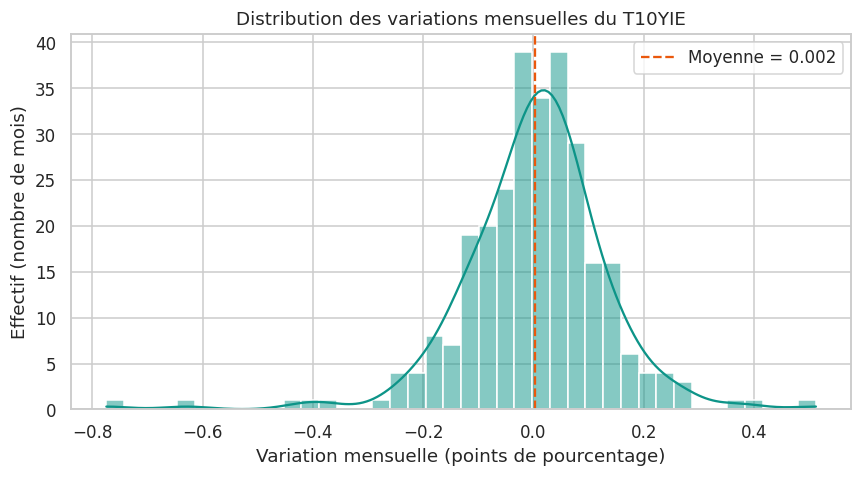

Plus fortes baisses :
 observation_date
2008-10-01   -0.77
2020-03-01   -0.63
2008-11-01   -0.42
Name: niveau, dtype: float64
Plus fortes hausses :
 observation_date
2009-02-01    0.51
2022-03-01    0.39
2009-01-01    0.36
Name: niveau, dtype: float64


In [13]:
var_m = monthly["niveau"].diff().dropna()

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(var_m, bins=40, kde=True, color="#0d9488", ax=ax)
ax.axvline(var_m.mean(), color="#ea580c", ls="--", label=f"Moyenne = {var_m.mean():.3f}")
ax.set_title("Distribution des variations mensuelles du T10YIE")
ax.set_xlabel("Variation mensuelle (points de pourcentage)")
ax.set_ylabel("Effectif (nombre de mois)")
ax.legend()
plt.tight_layout()
plt.show()

print("Plus fortes baisses :\n", var_m.nsmallest(3).round(2))
print("Plus fortes hausses :\n", var_m.nlargest(3).round(2))

Interprétation : les variations sont centrées sur zéro, comme pour une quasi marche aléatoire, mais avec des queues épaisses. Les mois extrêmes sont octobre 2008 (−0,77), mars 2020 (−0,63) et février 2009 (+0,51). Ce sont des événements réels, donc on les conserve. Ils justifient de rapporter aussi la MAE, moins sensible aux gros écarts que la RMSE.

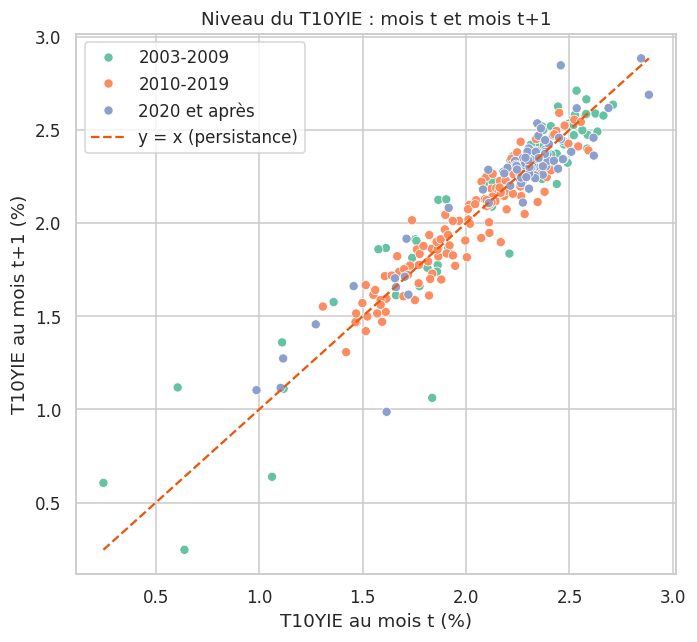

Corrélation t / t+1 : 0.942


In [14]:
tmp = pd.DataFrame({"t": monthly["niveau"], "t_plus_1": monthly["niveau"].shift(-1)}).dropna()
tmp["periode"] = np.where(tmp.index.year < 2010, "2003-2009",
                  np.where(tmp.index.year < 2020, "2010-2019", "2020 et après"))

fig, ax = plt.subplots(figsize=(6.5, 6))
sns.scatterplot(data=tmp, x="t", y="t_plus_1", hue="periode", ax=ax)
lims = [tmp[["t", "t_plus_1"]].min().min(), tmp[["t", "t_plus_1"]].max().max()]
ax.plot(lims, lims, color="#ea580c", ls="--", label="y = x (persistance)")
ax.set_title("Niveau du T10YIE : mois t et mois t+1")
ax.set_xlabel("T10YIE au mois t (%)")
ax.set_ylabel("T10YIE au mois t+1 (%)")
ax.legend()
plt.tight_layout()
plt.show()

print("Corrélation t / t+1 :", round(tmp["t"].corr(tmp["t_plus_1"]), 3))

Interprétation : les points sont très proches de la diagonale, avec une corrélation de 0,94. Le niveau du mois suivant ressemble beaucoup à celui du mois courant, donc la référence naïve (persistance) sera difficile à battre. Les écarts les plus grands se concentrent sur 2008-2009.


# Modèle et évaluation
